In [9]:
# Setup
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
import torch
from timesfm3 import TimesFM3Forecaster

device = "cuda" if torch.cuda.is_available() else "cpu"
pipeline = TimesFM3Forecaster.from_pretrained("google/timesfm-3.0-pytorch", device=device)

MODEL_LABEL = "TimesFM 3.0"
MAX_CONTEXT = pipeline.global_context
MAX_HORIZON = 1024
print(f"Loaded {MODEL_LABEL} on {device}")

Loaded TimesFM 3.0 on cpu


In [10]:
# Load data
DATA_FILE = "TEP_Run_Full_raw.h5"
SAMPLE_MIN = 3

FAULT_NAMES = {
    0: "Normal operation",
    1: "A/C feed ratio, B composition constant - step", 2: "B composition, A/C ratio constant - step",
    3: "D feed temperature - step", 4: "Reactor CW inlet temperature - step",
    5: "Condenser CW inlet temperature - step", 6: "A feed loss - step", 7: "C header pressure loss - step",
    8: "A, B, C feed composition - random walk", 9: "D feed temperature - random walk",
    10: "C feed temperature - random walk", 11: "Reactor CW inlet temperature - random walk",
    12: "Condenser CW inlet temperature - random walk", 13: "Reaction kinetics - slow drift",
    14: "Stripper steam heat transfer - random walk", 15: "Reactor heat transfer - pulse",
    16: "Condenser heat transfer - pulse", 17: "Reactor-separator flow - pulse",
    18: "Reactor CW valve - stiction", 19: "Condenser CW valve - stiction",
    20: "Recycle, separator, stripper product and steam valves - stiction",
}


def read_names(ds):
    return [n.decode() if isinstance(n, bytes) else str(n) for n in ds.attrs["names"]]


groups = {}
with h5py.File(DATA_FILE, "r") as f:
    time_h = f["t"][()] / 3600
    for key in ["xmeas", "xmv", "dist", "sp"]:
        groups[key] = (f[key][()], read_names(f[key]))
    groups["idv"] = (f["idv_effective"][()], read_names(f["idv_effective"]))
    if "y" in f:   # true valve positions
        groups["valve"] = (f["y"][:, 38:50], read_names(f["y"])[38:50])

idv = groups["idv"][0]
data = {"time_h": time_h, "fault": np.where(idv.any(axis=1), idv.argmax(axis=1) + 1, 0)}
COLUMNS, LABELS = {}, {}
for group, (values, labels) in groups.items():
    COLUMNS[group] = [f"{group}_{i}" for i in range(1, values.shape[1] + 1)]
    for col, v, label in zip(COLUMNS[group], values.T, labels):
        data[col] = v
        LABELS[col] = label

df = pd.DataFrame(data)
df.insert(0, "item_id", "tep")
df.insert(1, "timestamp", pd.date_range("2026-01-01", periods=len(df), freq=f"{SAMPLE_MIN}min"))

TARGET_COLUMNS = COLUMNS["xmeas"] + COLUMNS["xmv"]
print(f"{len(df)} samples ({time_h[-1]:.0f} h), {len(TARGET_COLUMNS)} targets, covariate groups: "
      + ", ".join(f"{g} ({len(COLUMNS[g])})" for g in COLUMNS if g not in ["xmeas", "xmv"]))
df.head()

7000 samples (350 h), 53 targets, covariate groups: dist (12), sp (20), idv (20), valve (12)


,item_id,timestamp,time_h,fault,xmeas_1,xmeas_2,xmeas_3,xmeas_4,xmeas_5,xmeas_6,...,valve_3,valve_4,valve_5,valve_6,valve_7,valve_8,valve_9,valve_10,valve_11,valve_12
0,tep,2026-01-01 00:00:00,0.05,0,0.250443,3694.275878,4545.281750,9.465081,26.984284,41.983241,...,24.557616,61.968017,22.026545,39.856891,38.633818,49.732650,47.449067,40.699926,15.824260,50.0
1,tep,2026-01-01 00:03:00,0.10,0,0.251453,3632.678836,4488.882745,9.350686,26.707894,42.350751,...,24.719641,61.365705,22.450776,39.924343,36.912108,47.824012,47.423683,41.447862,16.938379,50.0
2,tep,2026-01-01 00:06:00,0.15,0,0.266700,3682.753947,4520.385231,9.339925,26.773057,42.510097,...,26.237250,61.069972,22.270839,42.214411,35.383569,45.510612,47.439787,40.968363,18.850193,50.0
3,tep,2026-01-01 00:09:00,0.20,0,0.265710,3670.827830,4517.851523,9.355900,26.562167,42.478010,...,26.281674,61.102641,22.316714,42.503756,39.711471,46.903059,47.456291,41.185084,17.216113,50.0
4,tep,2026-01-01 00:12:00,0.25,0,0.230932,3696.279836,4570.795137,9.405088,26.807648,42.477210,...,22.654787,61.391893,21.855288,39.262261,32.671428,45.253206,47.469745,41.881026,18.163152,50.0


In [11]:
# Pick a forecast window
events = []   # (start index, end index, fault number)
for k in range(idv.shape[1]):
    on = idv[:, k] == 1
    for i in range(len(on)):
        if on[i] and (i == 0 or not on[i - 1]):
            start = i
        if on[i] and (i == len(on) - 1 or not on[i + 1]):
            events.append((start, i, k + 1))
events.sort()

for k, (s, e, f) in enumerate(events):
    print(f"{k:2d}  IDV {f:2d}  samples {s:4d}-{e:4d}  ({time_h[s]:5.1f}-{time_h[e]:5.1f} h)  {FAULT_NAMES[f]}")

EVENT_INDEX = 39
START = None
BUFFER = 20
HORIZON = 100
PLOT_LEAD_IN = 200

event_start, event_end, event_fault = events[EVENT_INDEX]
if START is None:
    SPLIT = max(event_start - BUFFER, 0)
    default_horizon = event_end - SPLIT + 100
else:
    SPLIT = START
    default_horizon = MAX_HORIZON
HORIZON = min(HORIZON or default_horizon, MAX_HORIZON, len(df) - SPLIT)
context_used = min(SPLIT, MAX_CONTEXT)

window_faults = [k + 1 for k in range(idv.shape[1]) if idv[SPLIT:SPLIT + HORIZON, k].any()]
print(f"\nForecast from sample {SPLIT} ({time_h[SPLIT]:.1f} h), horizon {HORIZON} samples ({HORIZON * SAMPLE_MIN / 60:.1f} h)")
print(f"Context: {SPLIT} samples available, {context_used} used (model max {MAX_CONTEXT})")
print(f"Faults in the forecast window: {window_faults if window_faults else 'none'}")

 0  IDV  1  samples  199- 278  ( 10.0- 13.9 h)  A/C feed ratio, B composition constant - step
 1  IDV  8  samples  373- 494  ( 18.7- 24.8 h)  A, B, C feed composition - random walk
 2  IDV 15  samples  578- 649  ( 28.9- 32.5 h)  Reactor heat transfer - pulse
 3  IDV  4  samples  709- 788  ( 35.5- 39.5 h)  Reactor CW inlet temperature - step
 4  IDV 11  samples  881- 969  ( 44.1- 48.5 h)  Reactor CW inlet temperature - random walk
 5  IDV 18  samples 1049-1128  ( 52.5- 56.5 h)  Reactor CW valve - stiction
 6  IDV  2  samples 1219-1298  ( 61.0- 65.0 h)  B composition, A/C ratio constant - step
 7  IDV 12  samples 1391-1472  ( 69.6- 73.7 h)  Condenser CW inlet temperature - random walk
 8  IDV 16  samples 1578-1677  ( 79.0- 83.9 h)  Condenser heat transfer - pulse
 9  IDV  5  samples 1729-1808  ( 86.5- 90.5 h)  Condenser CW inlet temperature - step
10  IDV 13  samples 1921-2063  ( 96.1-103.2 h)  Reaction kinetics - slow drift
11  IDV 20  samples 2069-2148  (103.5-107.5 h)  Recycle, separa

In [12]:
# Covariates
USE_DIST = True                  # disturbance signals (12)
USE_SP = False                   # set points (20)
USE_IDV = False                  # effective fault flags (20)
USE_VALVE = False                # true valve positions (12)
DROPPED = []
PAST_ONLY = []
COVARIATES_KNOWN_FUTURE = True

COVARIATE_COLUMNS = []
for group, use in [("dist", USE_DIST), ("sp", USE_SP), ("idv", USE_IDV), ("valve", USE_VALVE)]:
    if use and group in COLUMNS:
        COVARIATE_COLUMNS += COLUMNS[group]
COVARIATE_COLUMNS = [c for c in COVARIATE_COLUMNS if c not in DROPPED]

context_df = df.iloc[SPLIT - context_used:SPLIT]
truth_df = df.iloc[SPLIT:SPLIT + HORIZON]

window_df = pd.concat([context_df, truth_df])
constant = [c for c in COVARIATE_COLUMNS if window_df[c].nunique() == 1]
COVARIATE_COLUMNS = [c for c in COVARIATE_COLUMNS if c not in constant]

FUTURE_COV = [c for c in COVARIATE_COLUMNS if COVARIATES_KNOWN_FUTURE and c not in PAST_ONLY]
PAST_ONLY_COV = [c for c in COVARIATE_COLUMNS if c not in FUTURE_COV]

print(f"targets ({len(TARGET_COLUMNS)}): {', '.join(TARGET_COLUMNS)}")
print(f"past + future covariates ({len(FUTURE_COV)}): {', '.join(FUTURE_COV) or '-'}")
print(f"past-only covariates ({len(PAST_ONLY_COV)}): {', '.join(PAST_ONLY_COV) or '-'}")
if constant:
    print(f"left out, constant over the window ({len(constant)}): {', '.join(constant)}")

targets (53): xmeas_1, xmeas_2, xmeas_3, xmeas_4, xmeas_5, xmeas_6, xmeas_7, xmeas_8, xmeas_9, xmeas_10, xmeas_11, xmeas_12, xmeas_13, xmeas_14, xmeas_15, xmeas_16, xmeas_17, xmeas_18, xmeas_19, xmeas_20, xmeas_21, xmeas_22, xmeas_23, xmeas_24, xmeas_25, xmeas_26, xmeas_27, xmeas_28, xmeas_29, xmeas_30, xmeas_31, xmeas_32, xmeas_33, xmeas_34, xmeas_35, xmeas_36, xmeas_37, xmeas_38, xmeas_39, xmeas_40, xmeas_41, xmv_1, xmv_2, xmv_3, xmv_4, xmv_5, xmv_6, xmv_7, xmv_8, xmv_9, xmv_10, xmv_11, xmv_12
past + future covariates (11): dist_1, dist_2, dist_4, dist_5, dist_6, dist_7, dist_8, dist_9, dist_10, dist_11, dist_12
past-only covariates (0): -
left out, constant over the window (1): dist_3


In [13]:
# Run TimesFM 3.0
QUANTILES = [0.1, 0.5, 0.9]
VARIATES_PER_CALL = None

if VARIATES_PER_CALL is None:
    targets_per_call = len(TARGET_COLUMNS)
else:
    targets_per_call = VARIATES_PER_CALL - len(COVARIATE_COLUMNS)
    if targets_per_call < 1:
        raise ValueError(f"{len(COVARIATE_COLUMNS)} covariates leave no room for targets in {VARIATES_PER_CALL} series")

past_only_cov = None
if PAST_ONLY_COV:
    past_only_cov = context_df[PAST_ONLY_COV].to_numpy(dtype=np.float32).T                    # (covariates, context)
past_future_cov = None
if FUTURE_COV:
    past_future_cov = window_df[FUTURE_COV].to_numpy(dtype=np.float32).T                      # (covariates, context + horizon)

forecast, quantiles = [], []
for i in range(0, len(TARGET_COLUMNS), targets_per_call):
    chunk = TARGET_COLUMNS[i:i + targets_per_call]
    out = pipeline.predict(
        context_df[chunk].to_numpy(dtype=np.float32).T,                                       # (targets, context)
        horizon=HORIZON,
        past_only_covariates=past_only_cov,
        past_future_covariates=past_future_cov,
        return_quantiles=True,
    )
    forecast.append(out.forecast[:, :HORIZON])
    quantiles.append(out.quantiles[:, :HORIZON])
forecast = np.concatenate(forecast)     # (targets, horizon) median
quantiles = np.concatenate(quantiles)   # (targets, horizon, 9) deciles 0.1 .. 0.9

q_index = {q: pipeline.config.quantiles.index(q) for q in QUANTILES}
pred_df = pd.concat(
    [
        pd.DataFrame({
            "timestamp": truth_df["timestamp"].values,
            "time_h": truth_df["time_h"].values,
            "target_name": col,
            "predictions": forecast[v],
            **{str(q): quantiles[v, :, i] for q, i in q_index.items()},
        })
        for v, col in enumerate(TARGET_COLUMNS)
    ],
    ignore_index=True,
)
pred_df.head()

,timestamp,time_h,target_name,predictions,0.1,0.5,0.9
0,2026-01-14 12:57:00,325.00,xmeas_1,0.149796,0.126232,0.149796,0.174143
1,2026-01-14 13:00:00,325.05,xmeas_1,0.157954,0.129283,0.157954,0.186942
2,2026-01-14 13:03:00,325.10,xmeas_1,0.167554,0.136953,0.167554,0.197811
3,2026-01-14 13:06:00,325.15,xmeas_1,0.177219,0.145547,0.177219,0.208828
4,2026-01-14 13:09:00,325.20,xmeas_1,0.187032,0.153959,0.187032,0.219858


In [14]:
# Accuracy
normal_context = context_df[context_df["fault"] == 0]
in_fault = truth_df["fault"].to_numpy() != 0
last_value = context_df.iloc[-1]

rows = []
for col in TARGET_COLUMNS:
    pred = pred_df.loc[pred_df["target_name"] == col, "predictions"].to_numpy()
    actual = truth_df[col].to_numpy()
    scale = normal_context[col].std()
    if scale == 0:
        scale = np.nan
    err = pd.Series(np.abs(pred - actual) / scale)
    base_err = pd.Series(np.abs(last_value[col] - actual) / scale)
    rows.append({
        "variable": col,
        "description": LABELS[col],
        "MAE": np.abs(pred - actual).mean(),
        "scaled MAE (normal)": err[~in_fault].mean(),
        "scaled MAE (fault)": err[in_fault].mean(),
        "scaled MAE (all)": err.mean(),
        "baseline (normal)": base_err[~in_fault].mean(),
        "baseline (fault)": base_err[in_fault].mean(),
        "baseline (all)": base_err.mean(),
    })
accuracy = pd.DataFrame(rows).set_index("variable")

phases = ["normal", "fault", "all"]
summary = pd.DataFrame({
    MODEL_LABEL: [accuracy[f"scaled MAE ({p})"].mean() for p in phases],
    "last-value baseline": [accuracy[f"baseline ({p})"].mean() for p in phases],
    "samples": [(~in_fault).sum(), in_fault.sum(), len(in_fault)],
}, index=phases)
print(f"Mean scaled MAE over {accuracy['scaled MAE (all)'].notna().sum()} scored targets")
print(summary.round(3).to_string())
beats = (accuracy["scaled MAE (all)"] < accuracy["baseline (all)"]).sum()
print(f"{MODEL_LABEL} beats the baseline on {beats} / {accuracy['scaled MAE (all)'].notna().sum()} targets")
accuracy.sort_values("scaled MAE (all)", ascending=False).round(4)

Mean scaled MAE over 52 scored targets
        TimesFM 3.0  last-value baseline  samples
normal        0.712                0.895       60
fault         0.532                1.112       40
all           0.640                0.982      100
TimesFM 3.0 beats the baseline on 47 / 52 targets


,description,MAE,scaled MAE (normal),scaled MAE (fault),scaled MAE (all),baseline (normal),baseline (fault),baseline (all)
variable,,,,,,,,
xmeas_10,Purge rate (kscmh),0.1189,2.2129,1.4462,1.9062,2.6297,1.9595,2.3616
xmv_6,Purge valve,13.3207,2.0330,1.4060,1.7822,2.4873,2.0122,2.2973
xmeas_30,Purge B (mol%),0.5332,1.4066,2.2252,1.7340,1.8078,2.9107,2.2489
xmeas_24,Reactor feed B (mol%),0.3677,1.3699,2.1260,1.6724,1.7240,2.8881,2.1897
xmeas_40,Product G (mol%),0.5612,1.0877,0.9949,1.0506,1.2939,1.4158,1.3427
xmv_1,D feed flow,0.6501,1.1219,0.6198,0.9210,1.0526,0.6744,0.9013
xmeas_41,Product H (mol%),0.4387,0.8720,0.7923,0.8401,1.0636,1.1223,1.0871
xmeas_5,Recycle flow (kscmh),0.1736,0.8262,0.8355,0.8299,0.9114,0.9966,0.9455
xmeas_6,Reactor feed rate (kscmh),0.2324,0.9241,0.6883,0.8298,1.1658,0.8870,1.0542


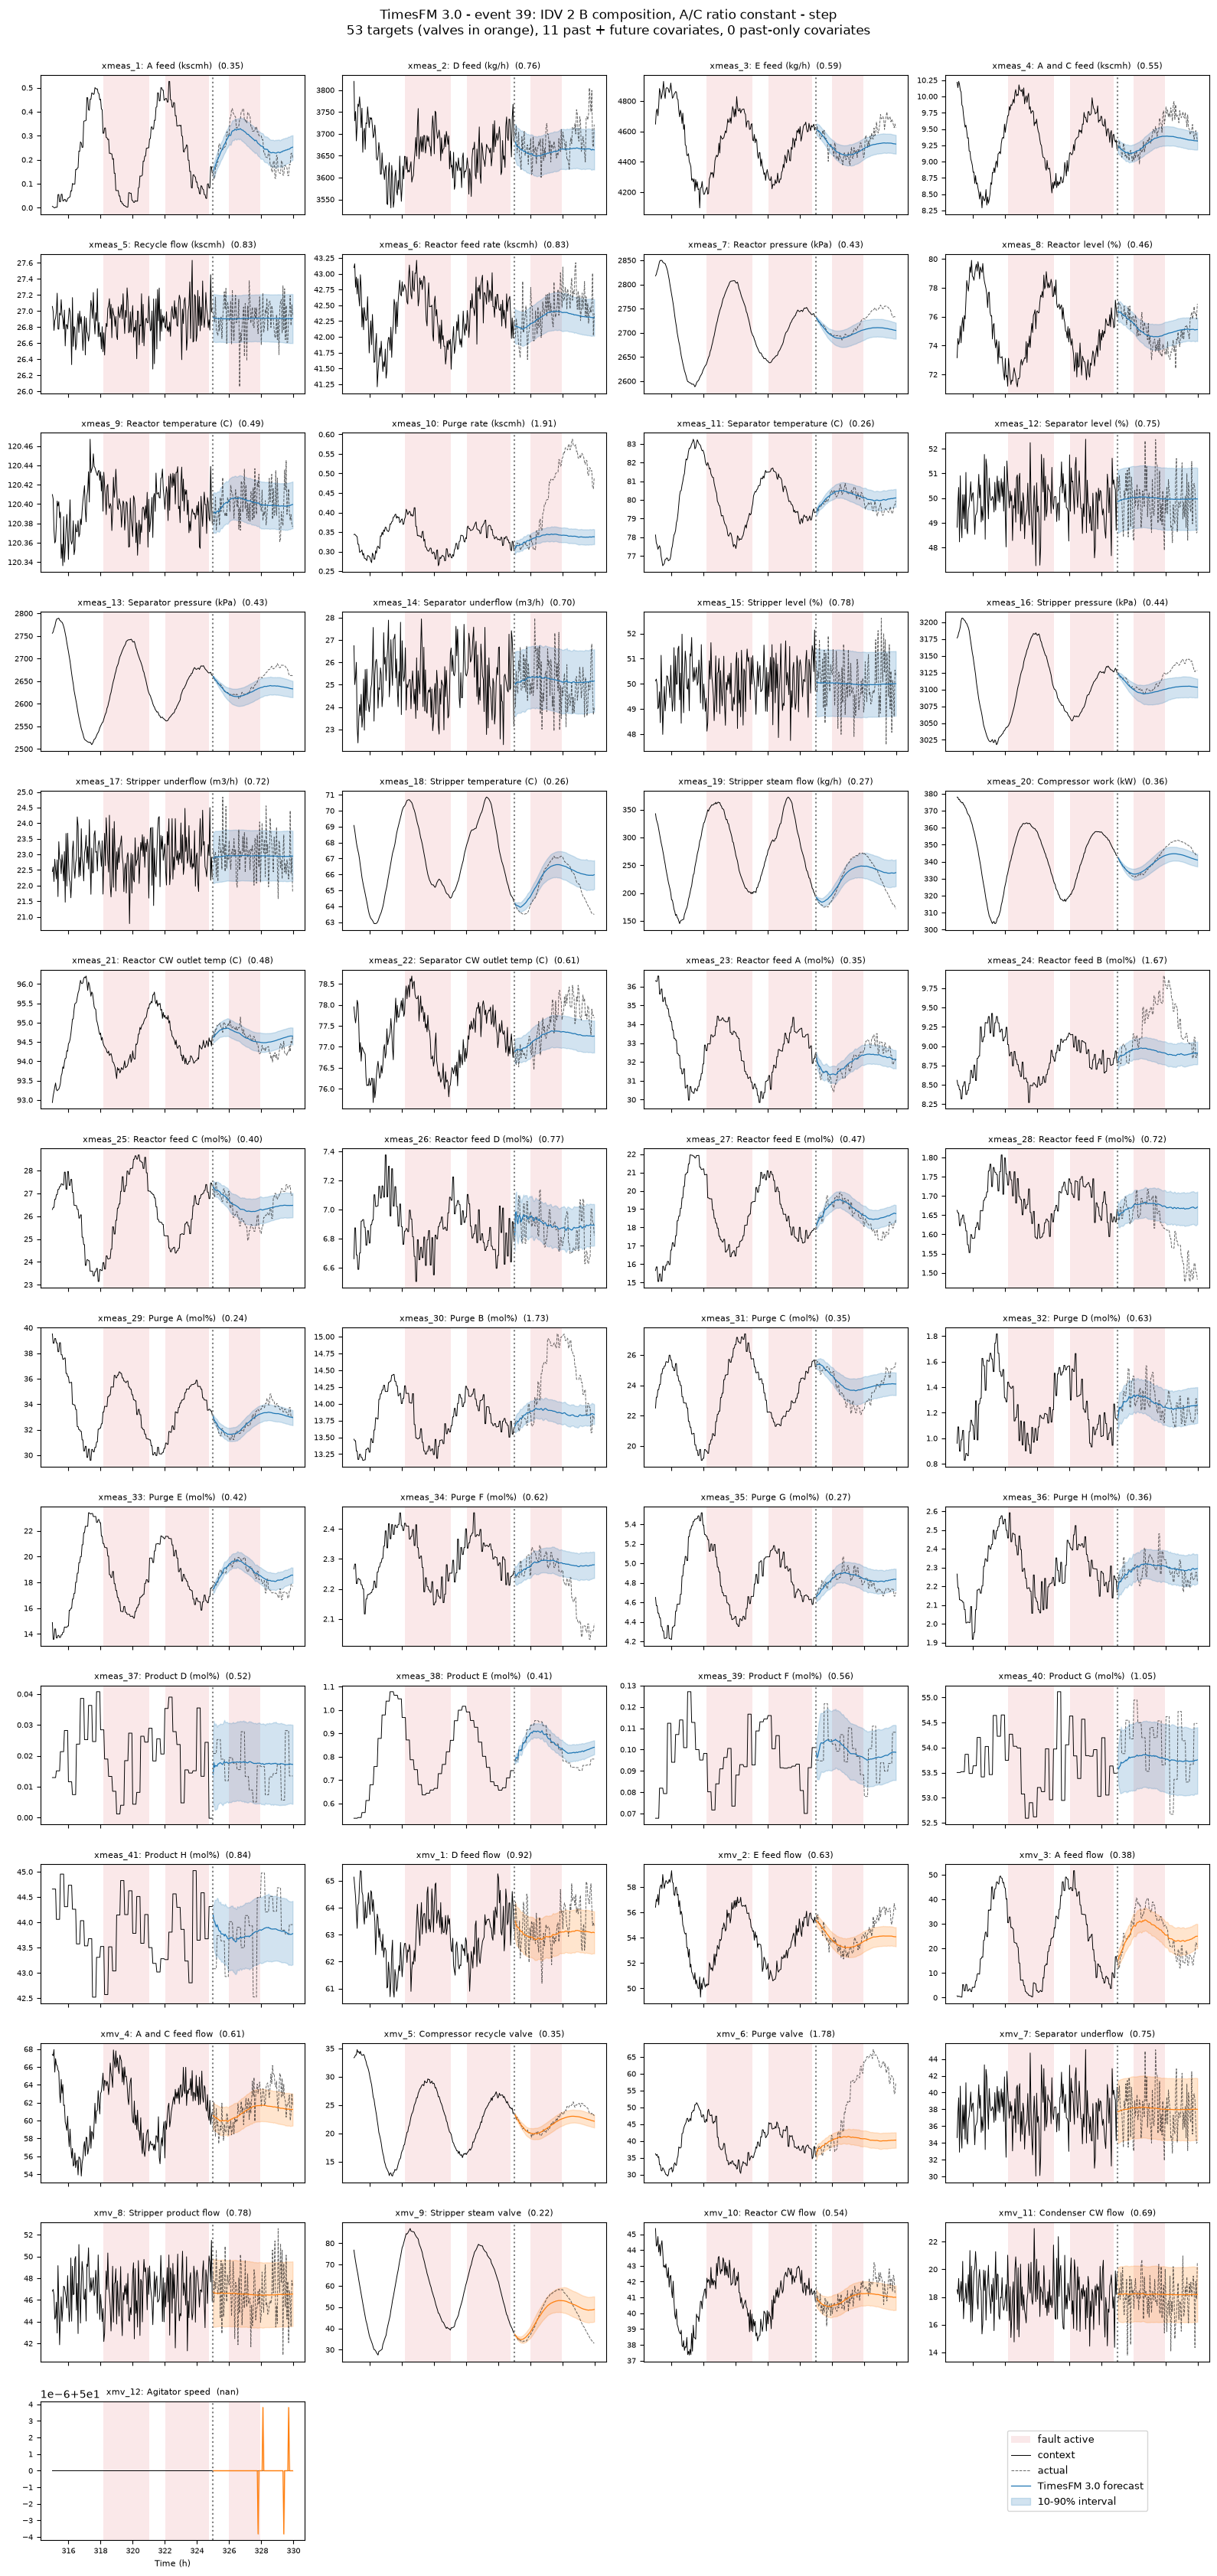

In [15]:
# Plot every target
lead = context_df.iloc[-PLOT_LEAD_IN:]
shown = pd.concat([lead, truth_df])

n_rows = -(-(len(TARGET_COLUMNS) + 1) // 4)
fig, axes = plt.subplots(n_rows, 4, figsize=(16, 2.4 * n_rows), sharex=True)
for ax, col in zip(axes.ravel(), TARGET_COLUMNS):
    sub = pred_df[pred_df["target_name"] == col]
    color = "tab:orange" if col.startswith("xmv") else "tab:blue"
    ax.fill_between(shown["time_h"], 0, 1, where=shown["fault"] != 0, color="tab:red", alpha=0.1,
                    transform=ax.get_xaxis_transform(), step="post", lw=0, label="fault active")
    ax.plot(lead["time_h"], lead[col], color="black", lw=0.7, label="context")
    ax.plot(truth_df["time_h"], truth_df[col], color="black", lw=0.7, ls="--", alpha=0.6, label="actual")
    ax.plot(sub["time_h"], sub["predictions"], color=color, lw=0.9, label=f"{MODEL_LABEL} forecast")
    ax.fill_between(sub["time_h"], sub["0.1"], sub["0.9"], color=color, alpha=0.2, label="10-90% interval")
    ax.axvline(truth_df["time_h"].iloc[0], color="gray", ls=":")
    ax.set_title(f"{col}: {LABELS[col]}  ({accuracy.loc[col, 'scaled MAE (all)']:.2f})", fontsize=8)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(TARGET_COLUMNS):]:
    ax.axis("off")
handles, labels = axes.ravel()[0].get_legend_handles_labels()
axes.ravel()[-1].legend(handles, labels, loc="center", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("Time (h)", fontsize=8)
fig.suptitle(f"{MODEL_LABEL} - event {EVENT_INDEX}: IDV {event_fault} {FAULT_NAMES[event_fault]}\n"
             f"{len(TARGET_COLUMNS)} targets (valves in orange), {len(FUTURE_COV)} past + future covariates, "
             f"{len(PAST_ONLY_COV)} past-only covariates", y=1.0)
fig.tight_layout()

In [16]:
# Save results
import json
import os

RESULTS_FILE = "Results/forecast_timesfm3.h5"
ACCURACY_COLUMNS = ["MAE", "scaled MAE (normal)", "scaled MAE (fault)", "scaled MAE (all)",
                    "baseline (normal)", "baseline (fault)", "baseline (all)"]

os.makedirs("Results", exist_ok=True)
with h5py.File(RESULTS_FILE, "w") as f:
    f.attrs["model"] = MODEL_LABEL
    f.attrs["settings"] = json.dumps({
        "data_file": DATA_FILE,
        "event_index": EVENT_INDEX,
        "split": int(SPLIT),
        "horizon": int(HORIZON),
        "future_covariates": FUTURE_COV,
        "past_only_covariates": PAST_ONLY_COV,
    })

    # Accuracy table
    f.create_dataset("variable", data=list(accuracy.index))
    f.create_dataset("description", data=list(accuracy["description"]))
    for name in ACCURACY_COLUMNS:
        f.create_dataset(name, data=accuracy[name].to_numpy())

    # Forecasts, actual values and the end of the context
    f.create_dataset("time_h", data=truth_df["time_h"].to_numpy())
    f.create_dataset("fault_active", data=truth_df["fault"].to_numpy() != 0)
    f.create_dataset("context_time_h", data=lead["time_h"].to_numpy())
    for col in TARGET_COLUMNS:
        sub = pred_df[pred_df["target_name"] == col]
        f.create_dataset(f"forecast/{col}", data=sub["predictions"].to_numpy())
        f.create_dataset(f"lower/{col}", data=sub["0.1"].to_numpy())
        f.create_dataset(f"upper/{col}", data=sub["0.9"].to_numpy())
        f.create_dataset(f"actual/{col}", data=truth_df[col].to_numpy())
        f.create_dataset(f"context/{col}", data=lead[col].to_numpy())
print(f"Saved {MODEL_LABEL} results to {RESULTS_FILE}")


Saved TimesFM 3.0 results to Results/forecast_timesfm3.h5
